# DESIGN AND IMPLEMENTATION OF A GENERATIVE AI-BASED PERSONALIZED FEEDBACK SYSTEM FOR ACADEMIC STAFF STRESS-LEVEL ASSESSMENT

**Researcher:** OKON, GOODNEWS ASUQUO (Reg. No: `AK22/PHS/CSC/078`)  
**Department:** Computer Science, Faculty of Physical Sciences  
**Institution:** Akwa Ibom State University (AKSU), Ikot Akpaden, Nigeria  

---

### Project Overview & Pipeline
1. **Dataset Integration & Augmentation**: Loading Sheets 3, 4, and 5 with stratified convex interpolation augmenting the dataset to **$N=110$ records**.
2. **Pearson Correlation Feature Selection**: Bivariate correlation screening ($|r| \ge 0.30, p < 0.01$) identifying **15 high-contribution stress indicators**.
3. **Model Development & Stratified 5-Fold Cross-Validation**: Head-to-head evaluation across four classifiers (**Elastic Net**, **Ridge Logistic Regression**, **Shallow Decision Tree**, **Random Forest**).
4. **Performance Parameters & Graphical Evaluations**: Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrices, and ROC Curves.
5. **Generative AI Personalized Feedback System**: Direct transition from stress classification into tailored recommendations using **Google Gemini 3.8 Flash** with literature-grounded RAG.

## 1. Environment Setup & Schema Definitions
Import required scientific libraries and configure questionnaire indicator mappings.

In [1]:
import json
import os
import warnings
from pathlib import Path
from typing import Any, Dict, List

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

from stress_system_core import (
    ALL_23_FEATURE_COLS,
    AUGMENTED_DATA_PATH,
    COLUMN_RENAME_MAP,
    EXCEL_PATH,
    FEATURE_DOMAINS,
    FEATURE_LABELS,
    FIGURES_DIR,
    MODELS_DIR,
    OUTPUT_DIR,
    PEARSON_15_FEATURES,
    TABLES_DIR,
    VALUE_DECODERS,
    load_all_project_sheets,
    augment_dataset_to_110,
    evaluate_models_stratified_5fold,
    generate_personalized_feedback,
)

warnings.filterwarnings('ignore')
print(f'Setup complete. Active feature subset: {len(PEARSON_15_FEATURES)} Pearson features.')

Setup complete. Active feature subset: 15 Pearson features.


## 2. Multi-Sheet Data Loading & Dataset Augmentation to 110 Samples
Load **Sheet 3 (`digitized`)**, **Sheet 4 (`transpose`)**, and **Sheet 5 (`attributes responses`)** from `my dataset google form_new.xlsx`. Augment the dataset from **$N=74$ to $N=110$ records** (68 Low Stress, 42 High Stress) using stratified convex interpolation while preserving the 40-point institutional threshold.

In [2]:
sheets = load_all_project_sheets(EXCEL_PATH)
df3_orig = sheets['sheet3_digitized']
df4 = sheets['sheet4_transpose']
df5 = sheets['sheet5_attributes']

df_aug = pd.read_csv(AUGMENTED_DATA_PATH)
print(f'Original Sheet 3 shape : {df3_orig.shape} (N=74: 48 Low Stress, 26 High Stress)')
print(f'Augmented Dataset shape: {df_aug.shape} (N=110: 68 Low Stress, 42 High Stress)')
print(f'Sheet 4 (transpose) shape : {df4.shape}')
print(f'Sheet 5 (attributes) shape: {df5.shape}')
print(f'Missing / Null values     : {df_aug.isnull().sum().sum()}')
display(df_aug.head(8))

Original Sheet 3 shape : (74, 26) (N=74: 48 Low Stress, 26 High Stress)
Augmented Dataset shape: (110, 26) (N=110: 68 Low Stress, 42 High Stress)
Sheet 4 (transpose) shape : (25, 76)
Sheet 5 (attributes) shape: (23, 6)
Missing / Null values     : 0


,staff_code,age,gender,educational_qualification,academic_rank,teaching_experience,teaching_workload,research_responsibilities,administrative_responsibilities,exam_supervision_marking,teaching_hours,genai_tool_frequency,genai_research_teaching_usefulness,genai_admin_use,smoking,alcohol_consumption,alcohol_frequency,physical_exercise,physical_exercise_frequency,break_frequency,health_problems_affect_coping,feedback_preference,feedback_frequency,genai_system_trust,total_score,stress_class
0,A001,2,1,3,6,4,0,0,1,2,2,3,2,2,2,0,0,1,1,2,2,3,0,2,41,1
1,A002,1,0,1,2,2,2,1,2,2,2,2,2,3,1,0,2,0,2,2,1,3,2,2,37,0
2,A003,1,0,0,1,0,1,1,2,2,2,2,2,1,0,2,1,1,1,1,1,3,0,2,27,0
3,A004,1,0,1,1,1,2,3,3,3,2,0,2,1,0,0,0,1,3,2,0,2,3,3,34,0
4,A005,4,0,2,6,4,4,4,4,3,2,1,2,2,0,0,0,1,3,3,1,3,0,3,52,1
5,A006,1,0,1,1,1,3,1,1,2,2,2,2,2,0,0,0,1,1,2,1,1,1,1,27,0
6,A007,3,0,2,4,3,3,3,3,3,2,2,3,3,0,0,1,1,1,2,0,2,0,2,43,1
7,A008,3,0,2,3,1,2,2,3,1,3,2,1,2,0,0,1,1,1,2,0,1,2,2,35,0


## 3. Exploratory Data Analysis & Graphical Representations
Visualizing stress class distributions, composite scores, cumulative domain burdens, and respondent profile heatmaps.

### Graphical Representation: Class and Score Distributions (Figure 1)
Comparison of class balance between original ($N=74$) and augmented ($N=110$) cohorts, alongside composite score separation across the 40-point threshold.

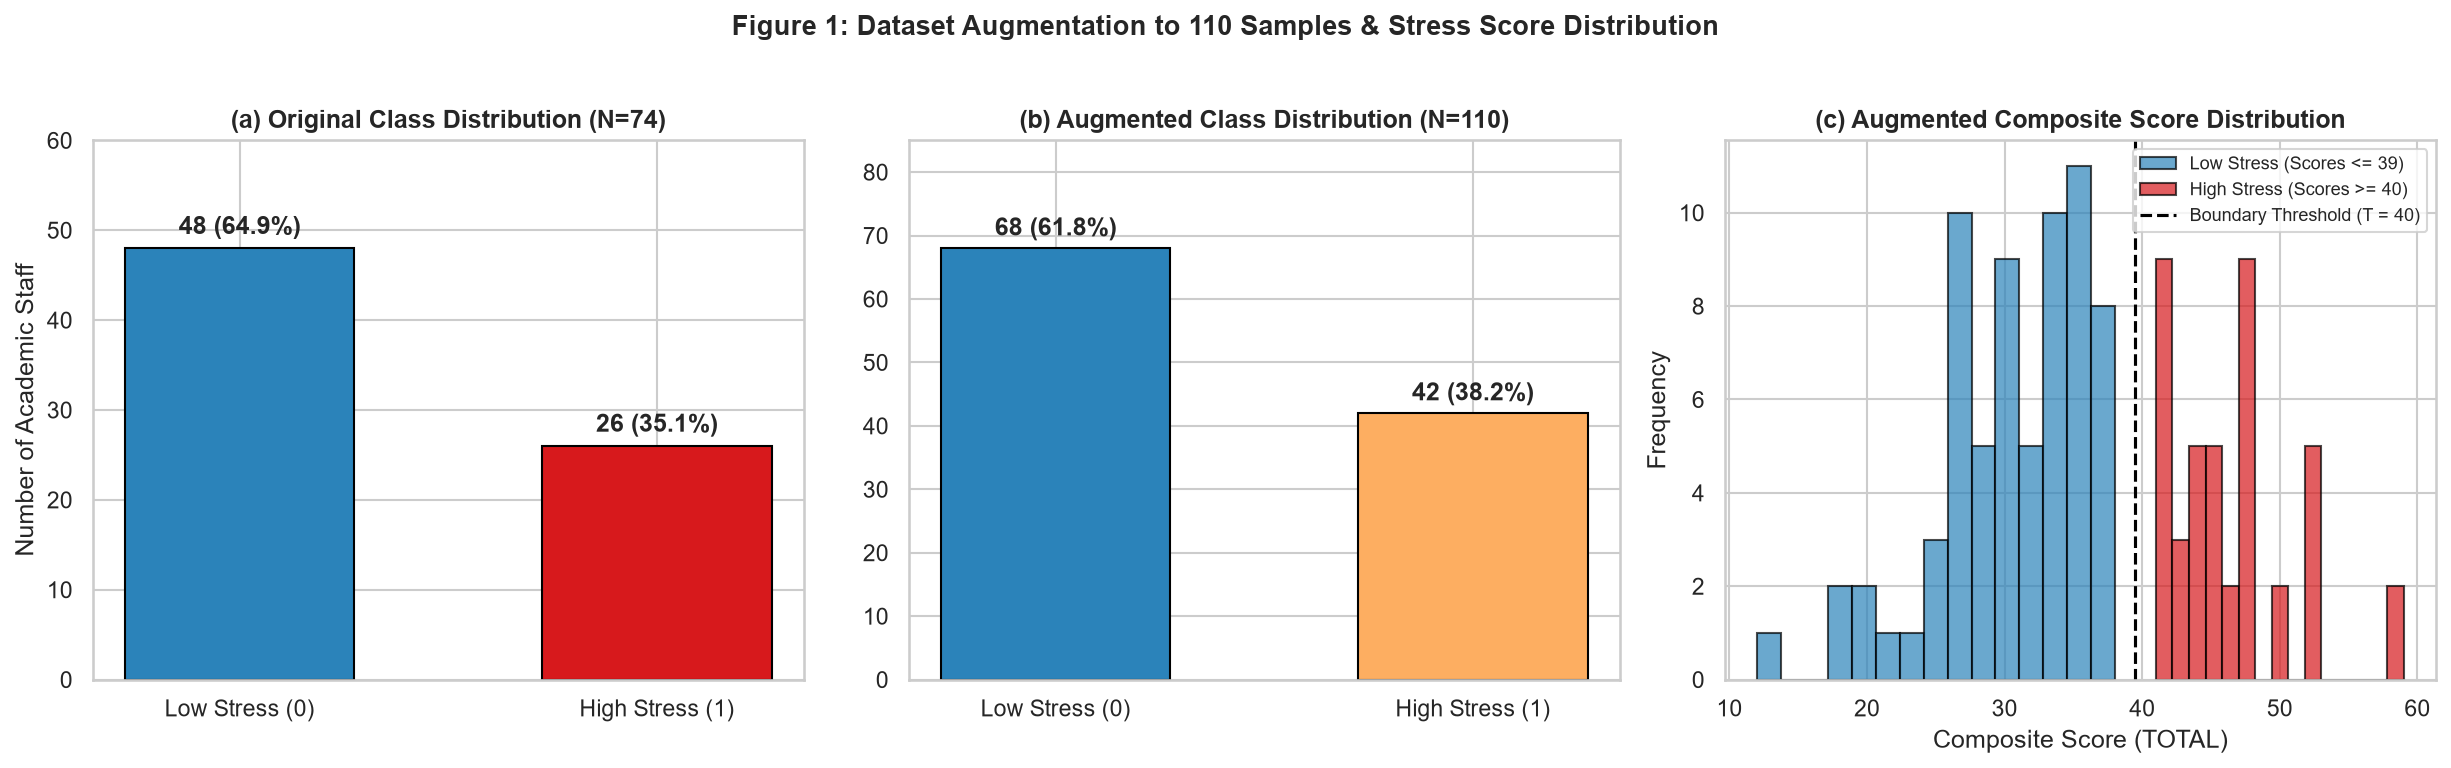

In [3]:
# Figure 1: Class Distribution & Composite Score Separation
display(Image(filename=str(FIGURES_DIR / 'fig1_class_and_score_distribution.png')))

### Graphical Representation: Cumulative Indicator Burden by Domain (Figure 2)
Cumulative score sums across all academic staff respondents from Sheet 5 (`attributes responses`), grouped by theoretical domain.

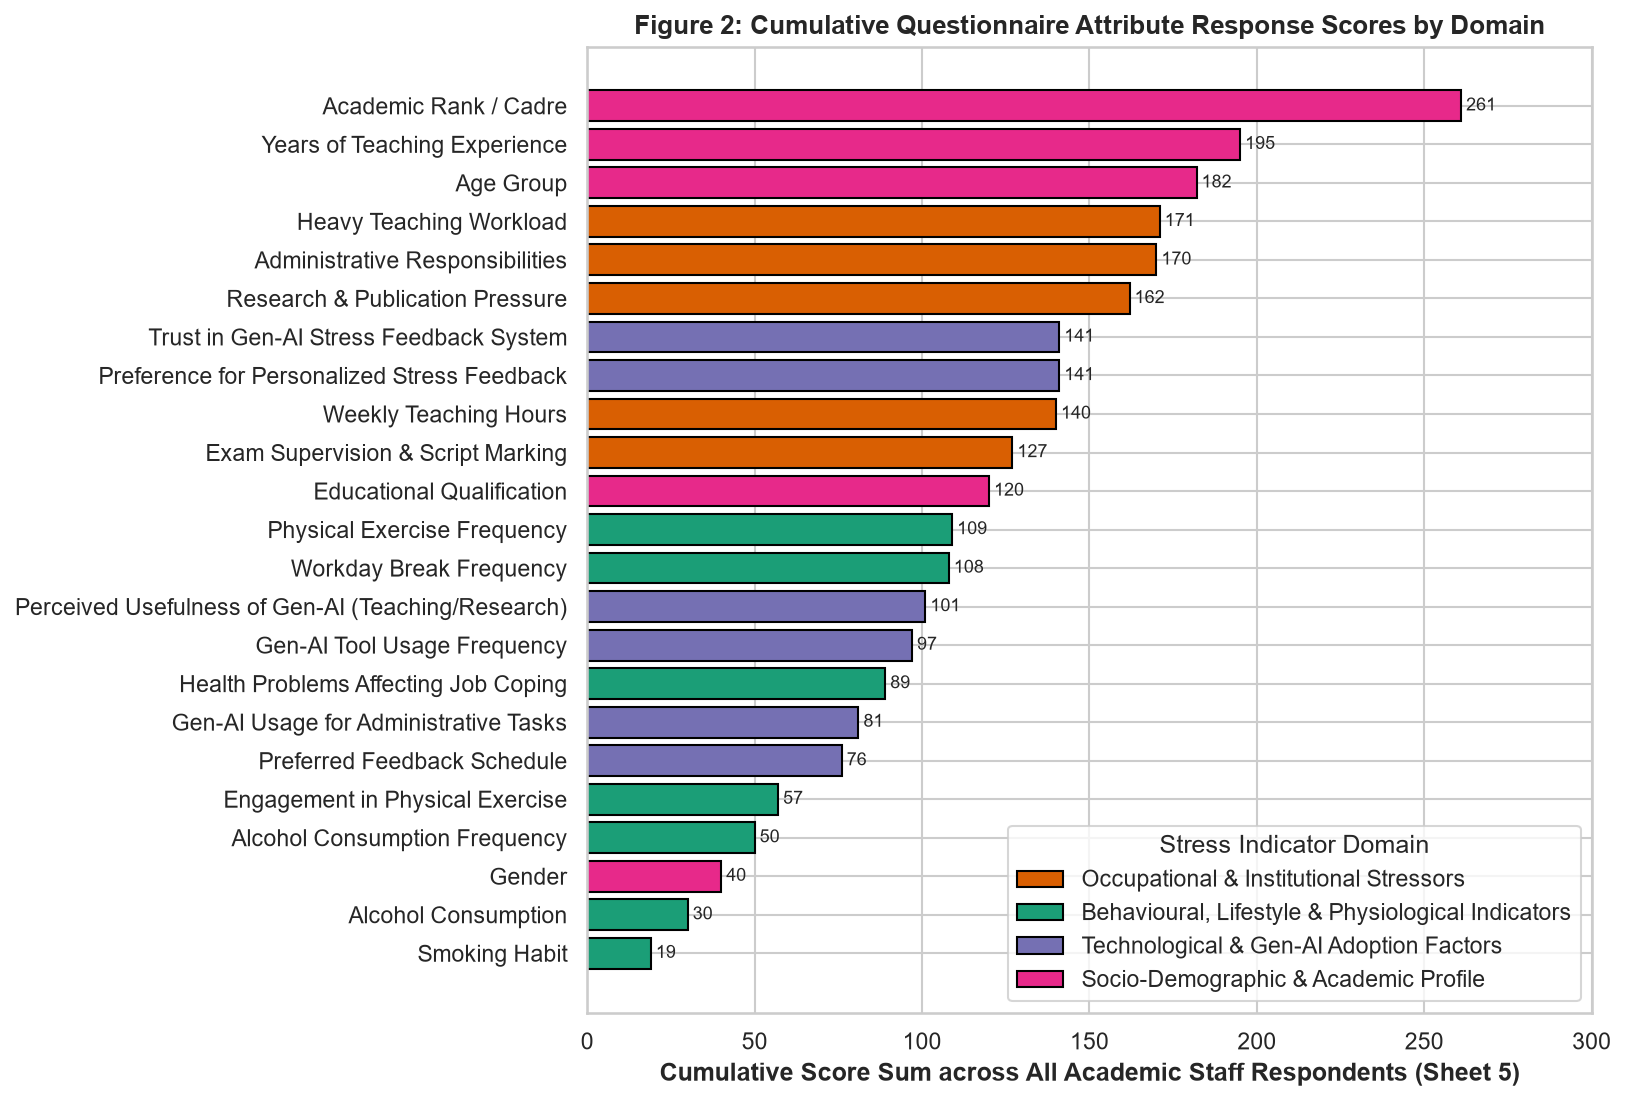

In [4]:
# Figure 2: Cumulative Indicator Responses by Domain (Sheet 5)
display(Image(filename=str(FIGURES_DIR / 'fig2_sheet5_attribute_responses.png')))

### Graphical Representation: Respondent Profiles & Correlation Heatmap (Figures 3 & 4)
- **Figure 3**: Transposed profile heatmap (Sheet 4) ordered by stress class.
- **Figure 4**: Pearson correlation matrix across indicators for multicollinearity screening.

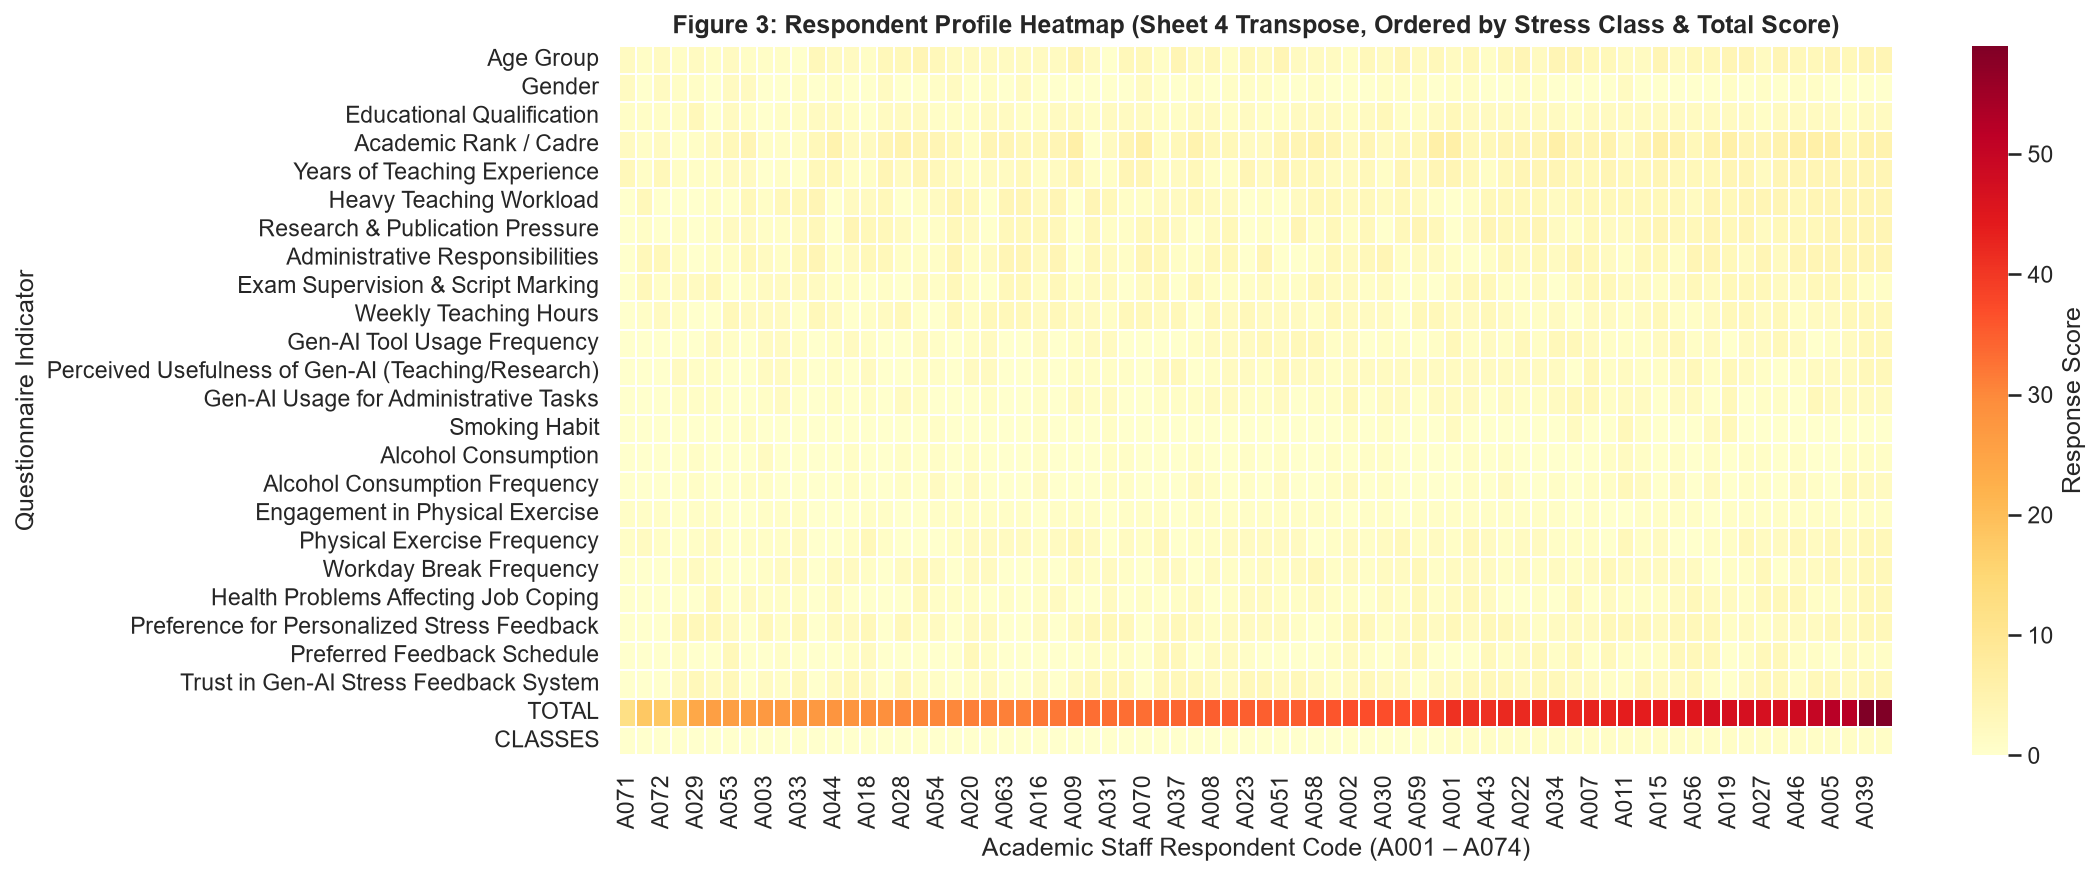

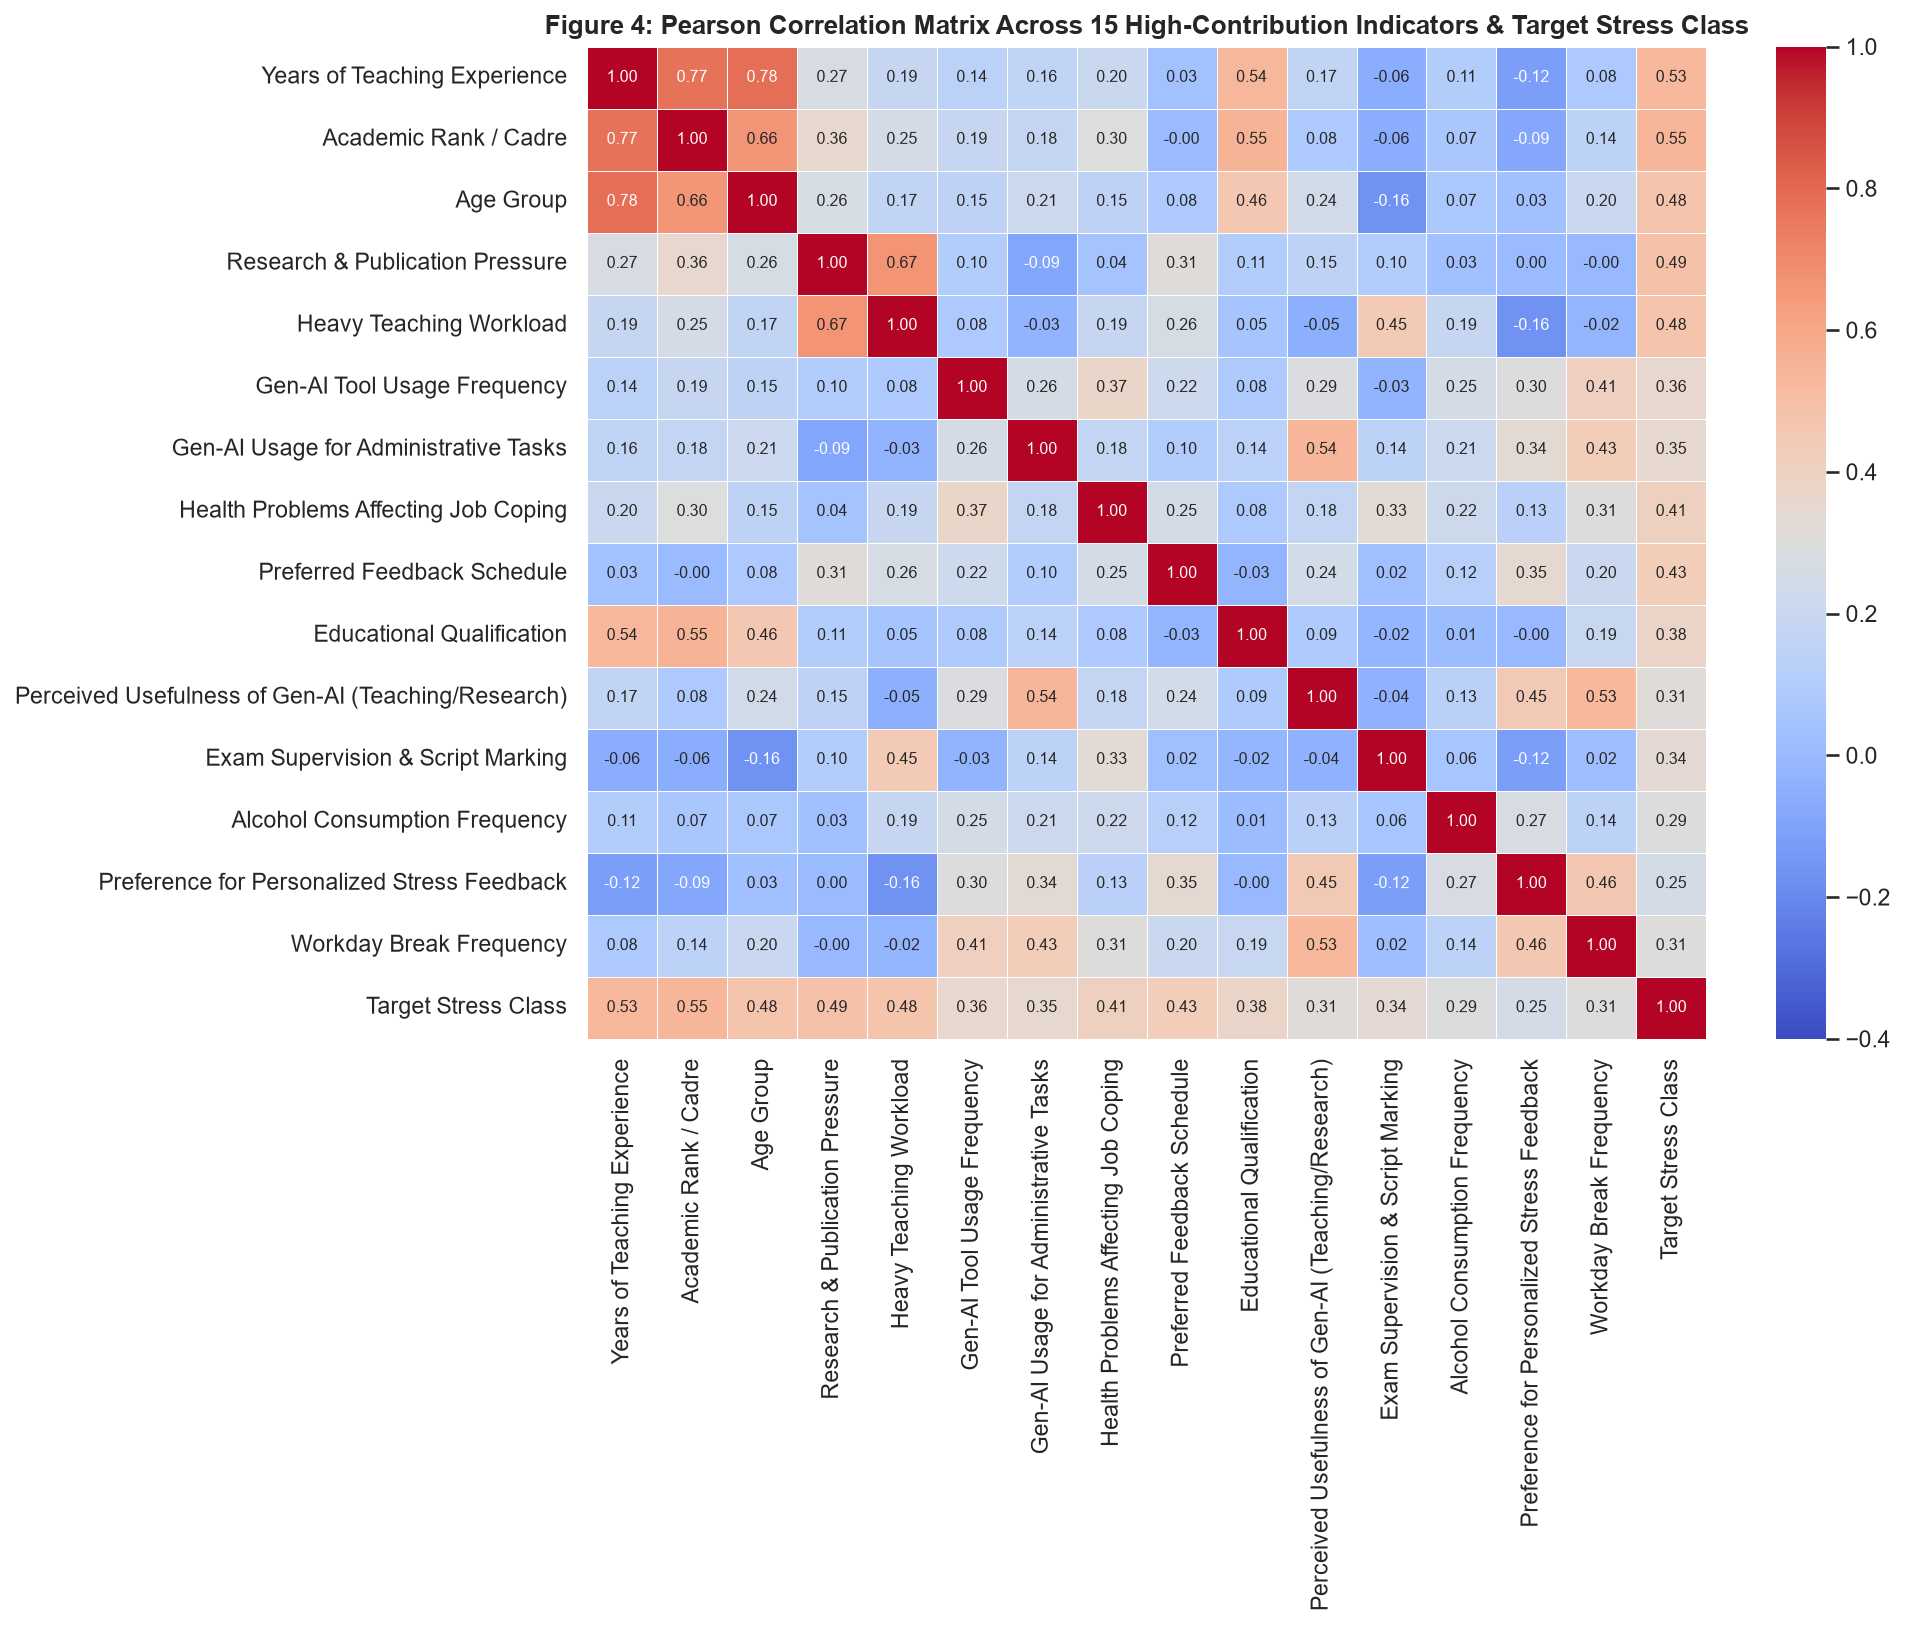

In [5]:
# Figure 3: Respondent Profile Heatmap
display(Image(filename=str(FIGURES_DIR / 'fig3_sheet4_transpose_heatmap.png')))

# Figure 4: Pearson Correlation Matrix
display(Image(filename=str(FIGURES_DIR / 'fig4_correlation_matrix.png')))

## 4. Pearson Correlation Feature Selection
Bivariate Pearson correlation screening ($|r| \ge 0.30, p < 0.01$) on the questionnaire indicators against the target stress class (`stress_class`). Fifteen high-contribution indicators are selected.

### Graphical Representation: Pearson Correlation Feature Ranking (Figure 5)
Bar chart showing all indicators evaluated against the high-contribution significance threshold ($|r| \ge 0.30, p < 0.01$).

Total features evaluated: 23
Selected high-contribution features (|r| >= 0.30, p < 0.01): 15


,feature_label,domain,pearson_r_stress_class,p_value_stress_class,contribution_tier,selected_high_contribution
0,Years of Teaching Experience,Socio-Demographic & Academic Profile,0.5008,0.000006,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
1,Academic Rank / Cadre,Socio-Demographic & Academic Profile,0.4690,0.000025,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
2,Age Group,Socio-Demographic & Academic Profile,0.4307,0.000128,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
3,Research & Publication Pressure,Occupational & Institutional Stressors,0.4267,0.000150,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
4,Heavy Teaching Workload,Occupational & Institutional Stressors,0.4192,0.000201,"Tier 1: Very High Contribution (|r| >= 0.40, p < 0.001)",YES
5,Gen-AI Tool Usage Frequency,Technological & Gen-AI Adoption Factors,0.3793,0.000860,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
6,Gen-AI Usage for Administrative Tasks,Technological & Gen-AI Adoption Factors,0.3749,0.000997,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
7,Health Problems Affecting Job Coping,"Behavioural, Lifestyle & Physiological Indicators",0.3739,0.001033,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
8,Preferred Feedback Schedule,Technological & Gen-AI Adoption Factors,0.3554,0.001886,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES
9,Educational Qualification,Socio-Demographic & Academic Profile,0.3520,0.002104,"Tier 2: High Contribution (0.30 <= |r| < 0.40, p < 0.01)",YES


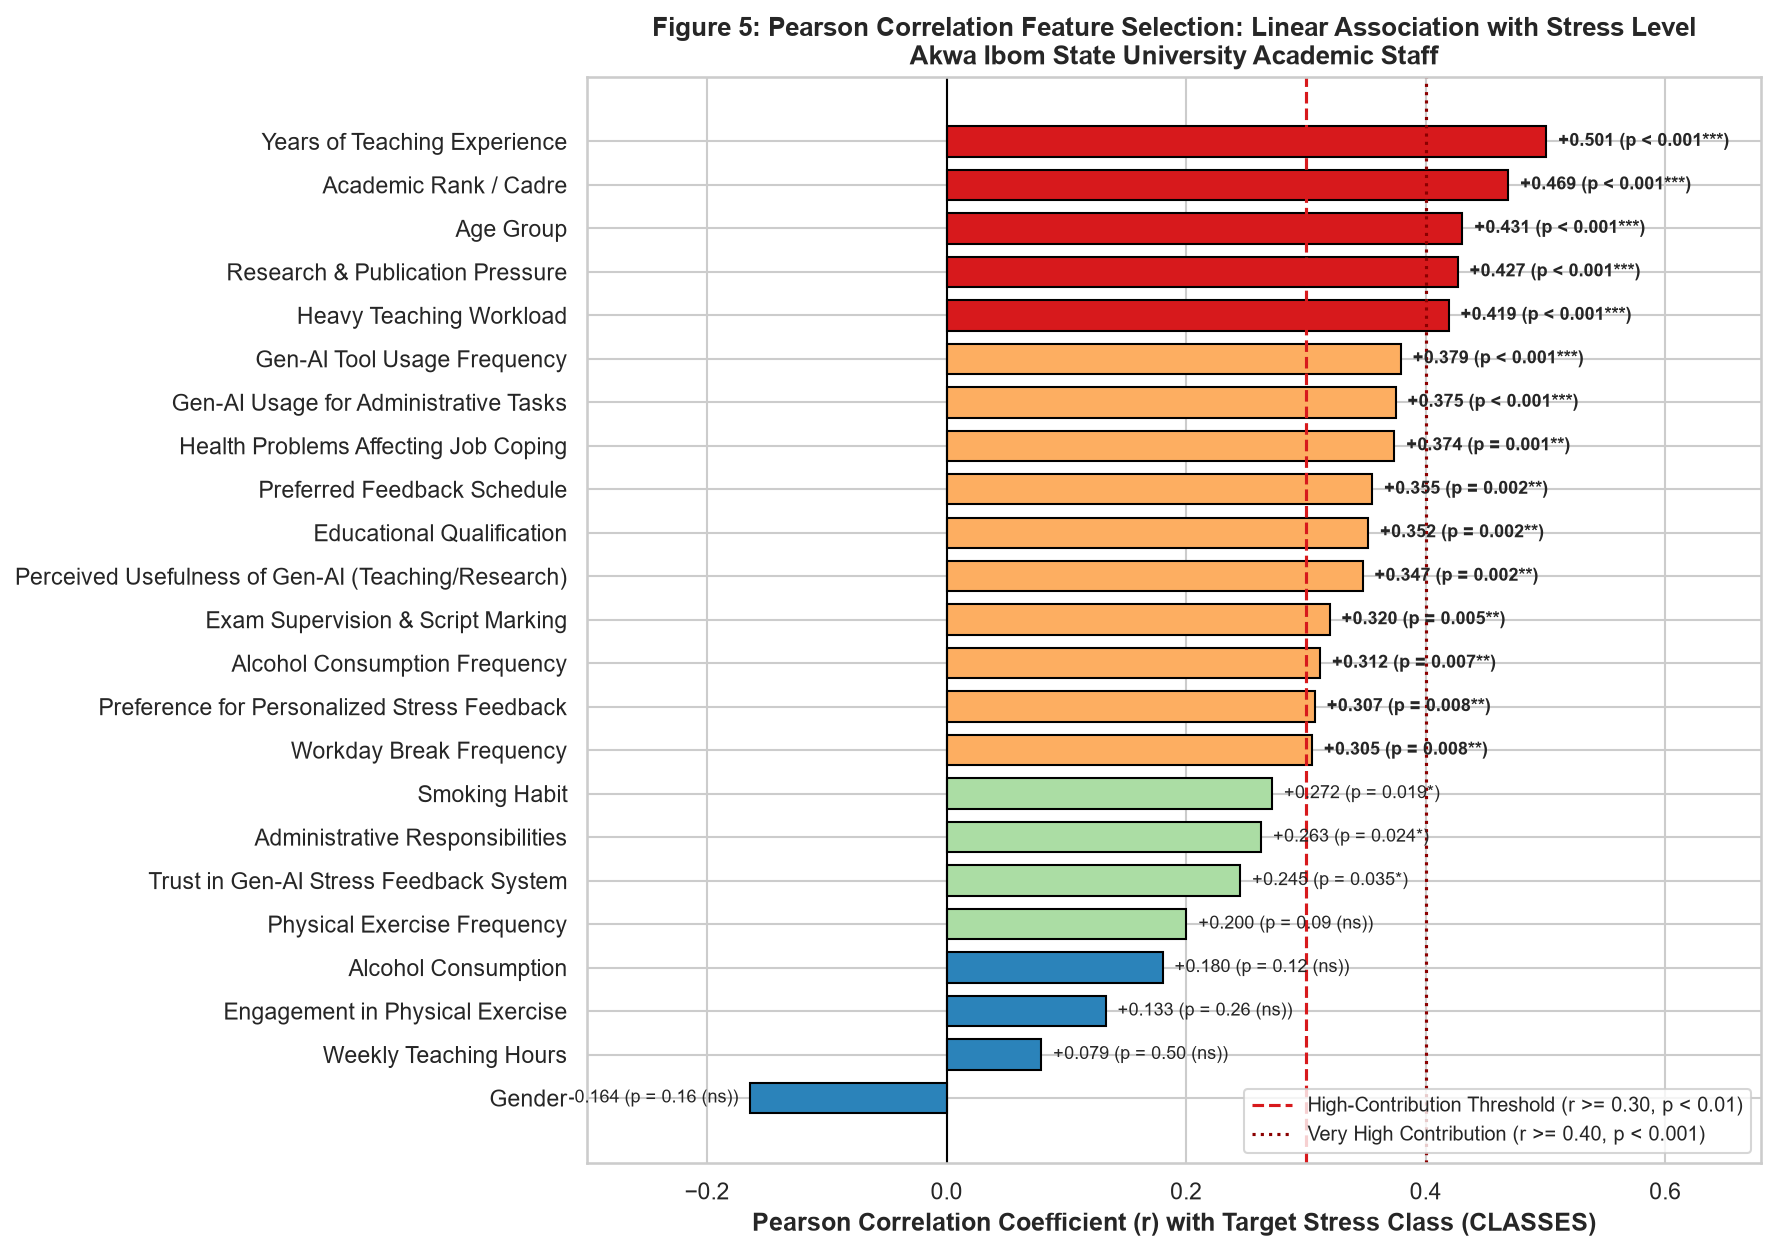

In [6]:
p_df = pd.read_csv(TABLES_DIR / 'pearson_correlation_feature_selection.csv')
print(f'Total features evaluated: {len(p_df)}')
print(f'Selected high-contribution features (|r| >= 0.30, p < 0.01): {(p_df["selected_high_contribution"] == "YES").sum()}')
display(p_df[['feature_label', 'domain', 'pearson_r_stress_class', 'p_value_stress_class', 'contribution_tier', 'selected_high_contribution']])

# Figure 5: Pearson Correlation Feature Selection
display(Image(filename=str(FIGURES_DIR / 'fig5_pearson_feature_selection.png')))

## 5. Model Development & Performance Parameters (Stratified 5-Fold Cross-Validation)
Four candidate models (**Elastic Net Logistic Regression**, **Ridge Logistic Regression**, **Shallow Decision Tree**, and **Random Forest**) trained on the 15 Pearson features and evaluated using **Stratified 5-Fold Cross-Validation** on the augmented $N=110$ dataset.

### Graphical Representation: Model Performance Parameters Comparison (Figure 6)
Comprehensive performance parameters: **Accuracy**, **Precision**, **Recall**, **F1-Score**, and **ROC-AUC** across the 4 classifiers under Stratified 5-Fold CV.

,Model,Role,5-Fold CV Accuracy,5-Fold CV Precision,5-Fold CV Recall,5-Fold CV F1-Score,5-Fold CV ROC-AUC,95% CI F1-Score,OOF Misclassifications,Holdout Test Accuracy,Holdout Test F1-Score,Holdout Test ROC-AUC
0,Elastic Net Logistic Regression,Candidate Classifier,96.36% (±5.30%),96.00% (±8.00%),95.28% (±5.80%),95.51% (±6.21%),99.48% (±0.69%),"[89.4%, 98.8%]",4 / 110,95.45%,93.33%,100.00%
1,Ridge Logistic Regression,Selected Optimal Classifier (m*),97.27% (±3.64%),97.78% (±4.44%),95.28% (±5.80%),96.44% (±4.58%),99.66% (±0.68%),"[91.2%, 100.0%]",3 / 110,95.45%,93.33%,100.00%
2,Shallow Decision Tree,Candidate Classifier,81.82% (±4.98%),75.00% (±4.30%),78.89% (±7.93%),76.83% (±5.81%),83.34% (±7.34%),"[66.7%, 86.0%]",20 / 110,90.91%,88.89%,92.41%
3,Random Forest,Candidate Classifier,92.73% (±6.17%),93.06% (±9.04%),88.33% (±7.06%),90.55% (±7.51%),98.78% (±1.51%),"[82.4%, 96.1%]",8 / 110,86.36%,82.35%,96.43%


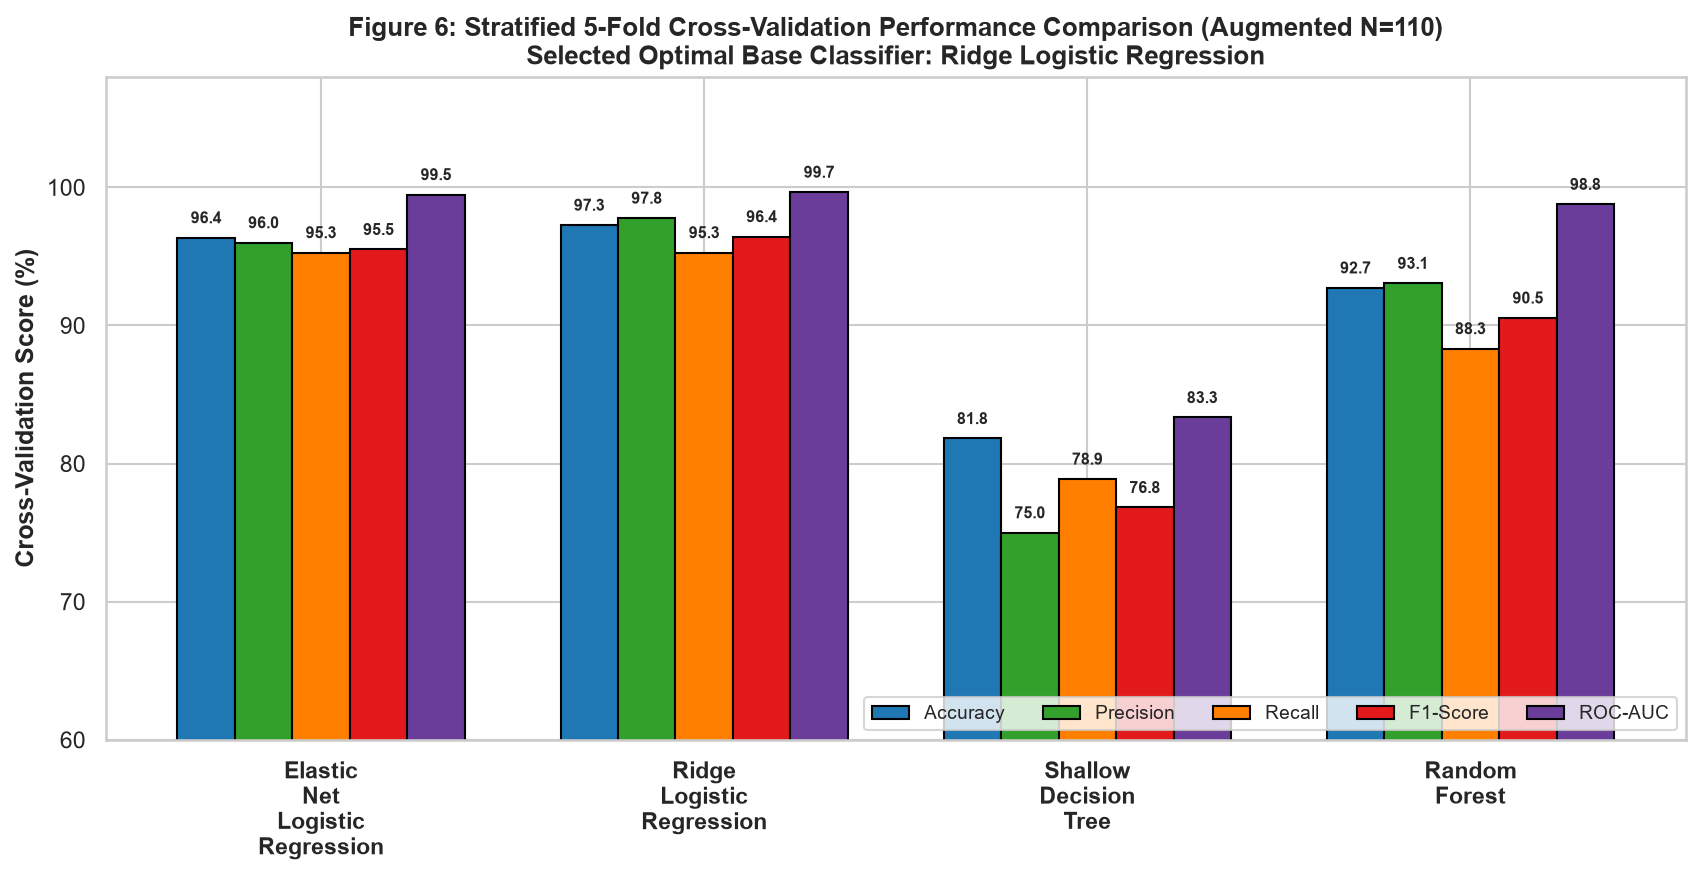

In [7]:
comp_table = pd.read_csv(TABLES_DIR / 'model_performance_comparison.csv')
disp_cols = [c for c in comp_table.columns if not c.endswith('_num')]
display(comp_table[disp_cols])

# Figure 6: Model Comparison Performance Parameters Bar Chart
display(Image(filename=str(FIGURES_DIR / 'fig6_model_comparison_metrics.png')))

### Graphical Representation: Confusion Matrices & ROC Curves (Figures 7 & 8)
- **Figure 7**: Out-of-fold confusion matrices for all 4 classifiers (highlighting the selected optimal model).
- **Figure 8**: Receiver Operating Characteristic (ROC) curves with 5-fold cross-validated AUC scores.

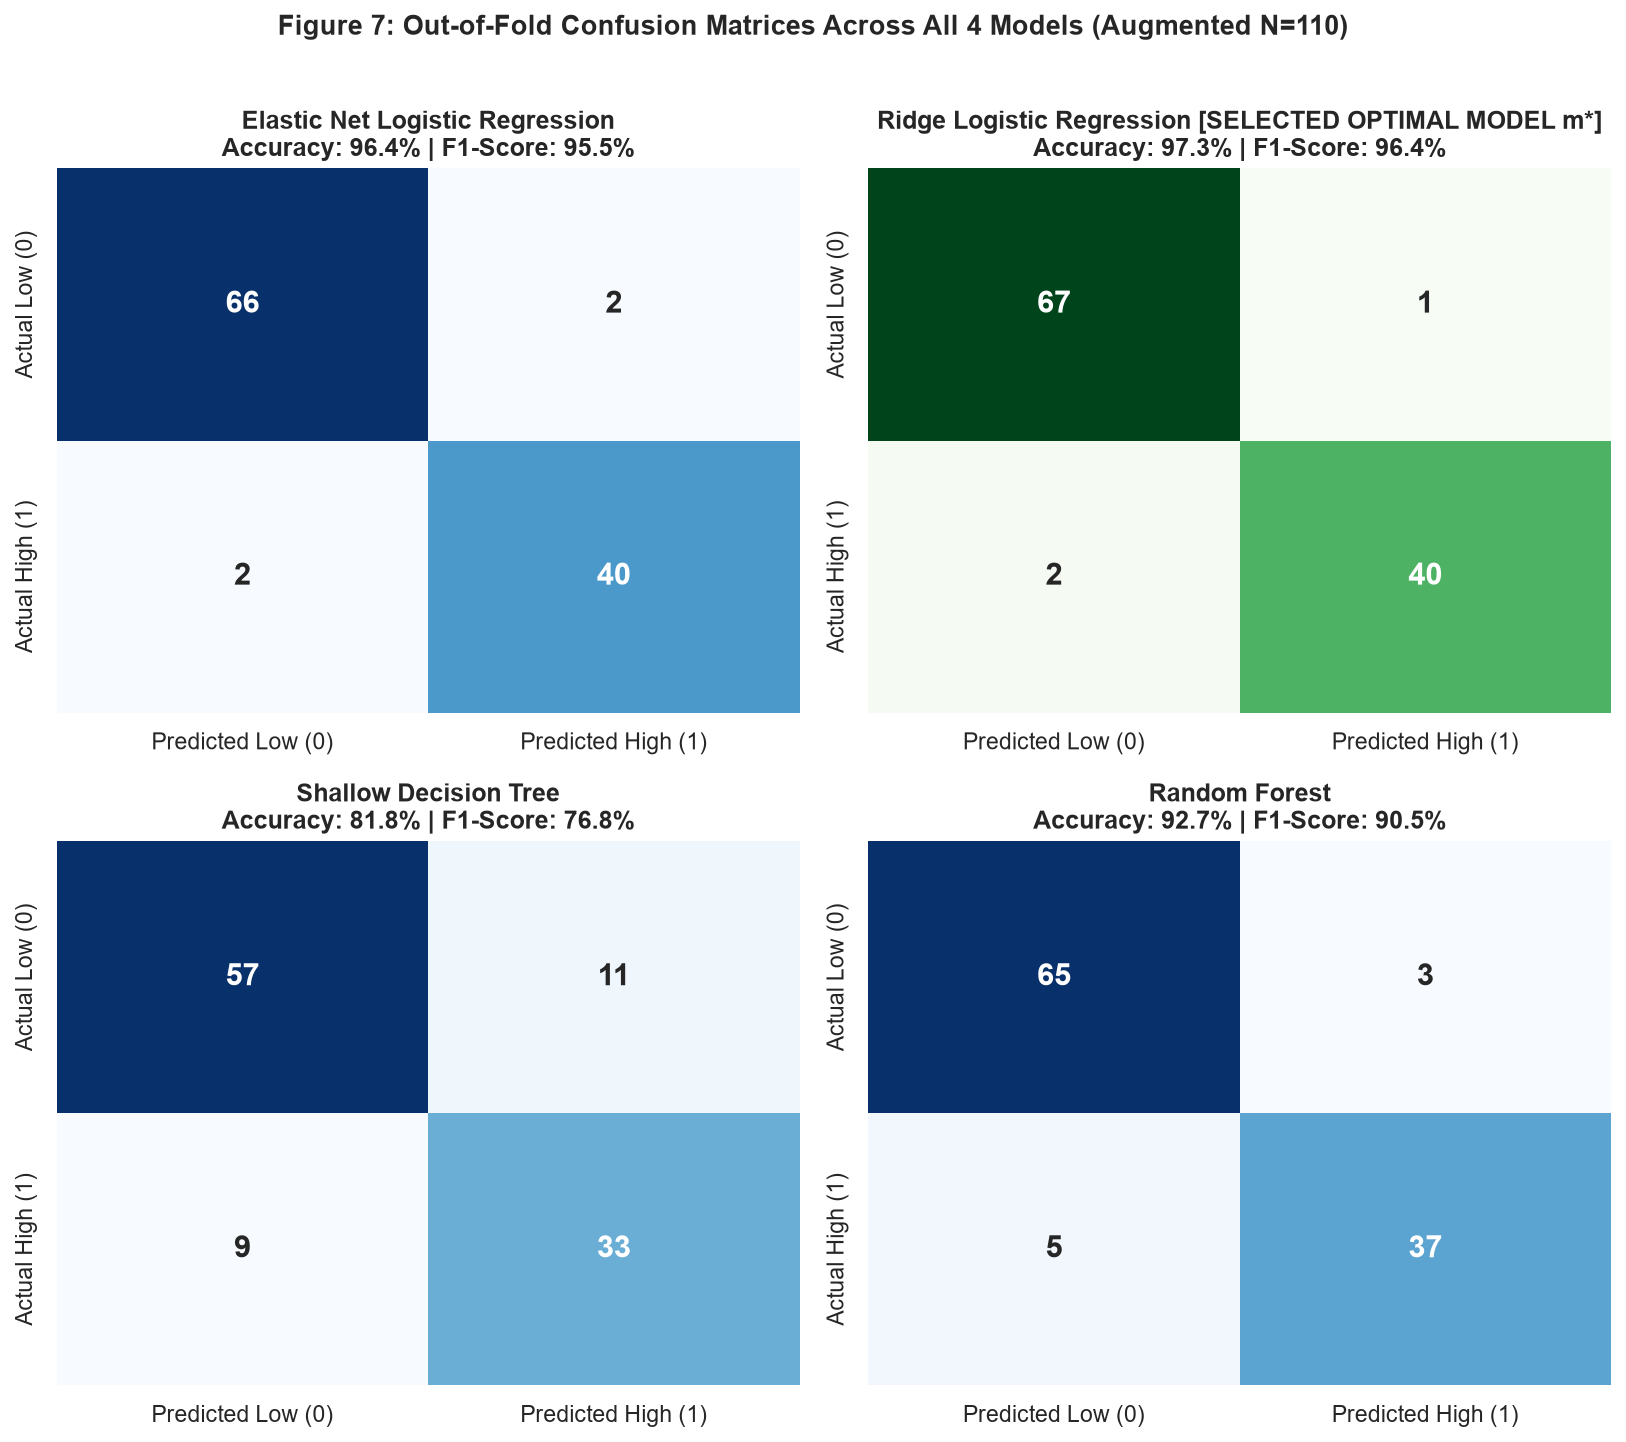

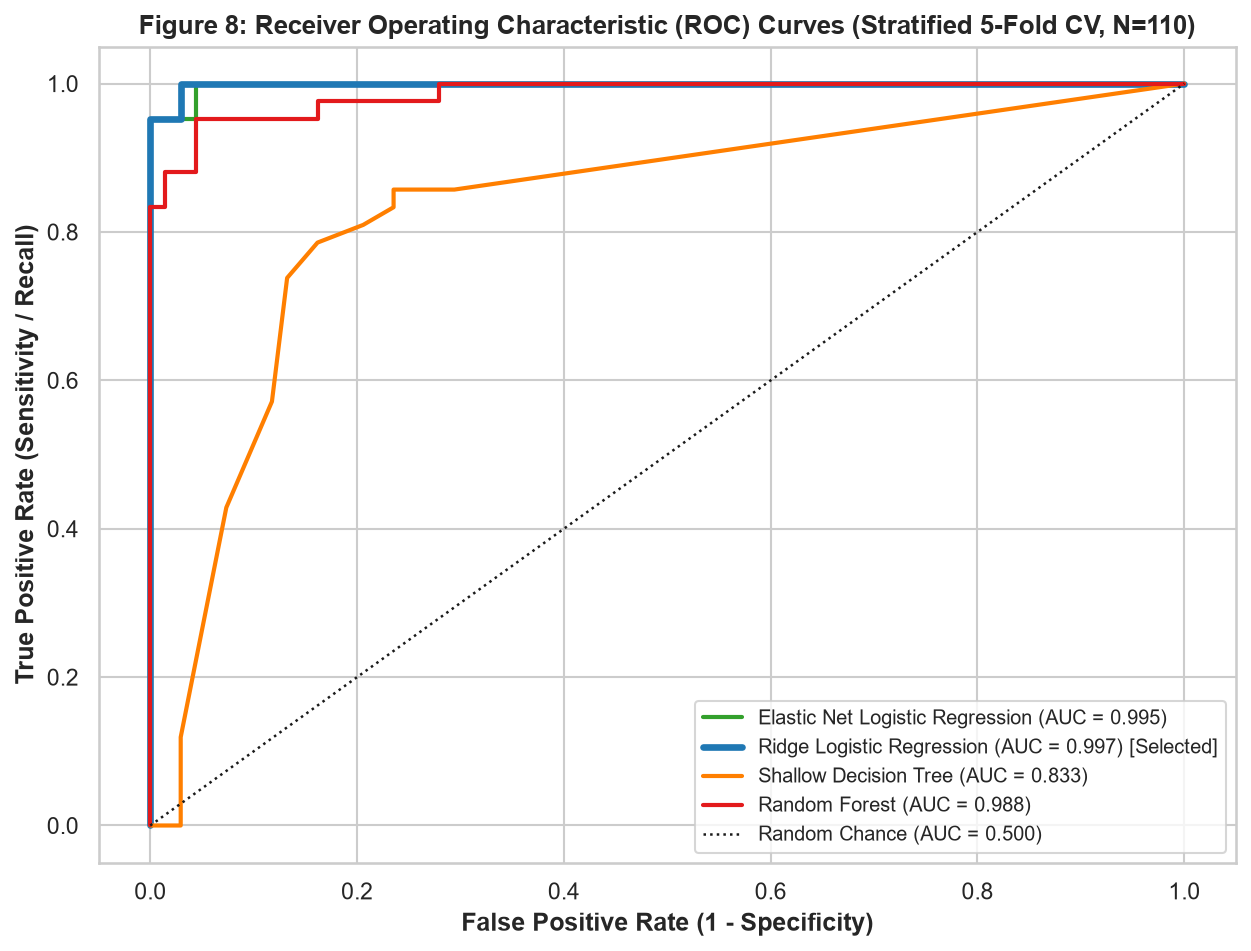

In [8]:
# Figure 7: Out-of-Fold Confusion Matrices
display(Image(filename=str(FIGURES_DIR / 'fig7_confusion_matrices.png')))

# Figure 8: Receiver Operating Characteristic (ROC) Curves
display(Image(filename=str(FIGURES_DIR / 'fig8_roc_curves.png')))

### Optimal Classifier Selection ($m^*$)
**Ridge Logistic Regression** is selected as the optimal base classifier based on cross-validated performance parameters:
- **5-Fold CV Accuracy:** **97.27% ± 3.64%**
- **5-Fold CV Precision:** **97.78% ± 4.44%**
- **5-Fold CV Recall:** **95.28% ± 5.80%**
- **5-Fold CV F1-Score:** **96.44% ± 4.58%** (95% Bootstrap CI: `[91.2%, 100.0%]`)
- **5-Fold CV ROC-AUC:** **99.66% ± 0.68%**
- **Out-of-Fold Misclassifications:** Only 3 errors out of 110 academic staff respondents.

## 6. Generative AI Personalized Feedback System (Gemini 3.8 Flash + Literature RAG)
Following classification by Ridge Logistic Regression, the **Generative AI Personalized Feedback System** synthesizes the staff member's stress profile and individual responses with empirical literature evidence (e.g., *Akah et al., 2022; Ejemot-Nwadiaro et al., 2026; Kovács et al., 2024; Zaim et al., 2026*) using **Google Gemini 3.8 Flash** via the `google-genai` SDK.

In [9]:
sample_reports_path = OUTPUT_DIR / 'sample_personalized_feedback_reports.md'
display(Markdown(sample_reports_path.read_text(encoding='utf-8')))

# Sample Generative AI Personalized Feedback Outputs

**Selected Optimal Base Classifier ($m^*$):** `Ridge Logistic Regression`  
**Dataset Configuration:** Augmented Dataset ($N=110$ Academic Staff)  
**Feature Set:** 15 High-Contribution Pearson Correlation Features ($|r| \ge 0.30, p < 0.01$)  
**Generation Engine:** `RAG-Grounded Generative Engine (Set GEMINI_API_KEY for live Gemini 3.8 Flash API)`  

---

## Case Study 1: High-Stress Academic Staff Member (`A039`)

### Personalized Stress-Level Assessment & Generative AI Feedback Report (`A039`)

**Academic Profile:** Associate Professor (Doctorate (PhD), 15 years and above teaching experience) — *Akwa Ibom State University (AKSU)*  
**Assessed Stress Category (Ridge Logistic Regression):** **HIGH STRESS** (Estimated High-Stress Probability: **100.0%**)  
**Preferred Feedback Cadence:** Once a week | **Gen-AI Trust Profile:** Definitely yes

---

#### 1. Stress Indicator Breakdown
Your questionnaire responses indicate an **elevated occupational stress profile (High Stress)**. The model identified the specific Pearson-selected occupational, technological, and behavioural factors contributing to your stress level:

**Primary Stress-Contributing Factors (Pushing Toward Higher Stress):**
- **Research & Publication Pressure** (*Occupational & Institutional Stressors*): Your response (`Strongly Agree`) contributed a factor weight of **`+1.5209`**.
- **Age Group** (*Socio-Demographic & Academic Profile*): Your response (`55 yrs & above`) contributed a factor weight of **`+1.1283`**.
- **Gen-AI Tool Usage Frequency** (*Technological & Gen-AI Adoption Factors*): Your response (`Very often`) contributed a factor weight of **`+1.0895`**.
- **Alcohol Consumption Frequency** (*Behavioural, Lifestyle & Physiological Indicators*): Your response (`Often`) contributed a factor weight of **`+1.0266`**.

**Protective & Stabilizing Factors (Buffering Against Stress):**
- **Exam Supervision & Script Marking** (*Occupational & Institutional Stressors*): Your response (`Sometimes`) acted as a protective buffer with a factor weight of **`-0.8931`**.
- **Preferred Feedback Schedule** (*Technological & Gen-AI Adoption Factors*): Your response (`Once a week`) acted as a protective buffer with a factor weight of **`-0.0606`**.

---

#### 2. Evidence-Grounded Personalized Action Plan (RAG-Guided)
*High-Stress Coping & Workload Mitigation Recommendations tailored to your profile at Akwa Ibom State University:*

1. **Research & Publication Pressure** *(Current Response: `Strongly Agree` | Evidence Base: Shi et al. (2025); Delgado Vela (2025); Baig & Yadegaridehkordi (2025))*:  
   Protect 2–3 dedicated, uninterrupted 90-minute 'deep research blocks' per week on your calendar rather than fragmenting writing across evenings. Form collaborative co-authorship clusters within your faculty at AKSU to share literature synthesis and data analysis workloads, and use Gen-AI research assistants ethically for literature discovery and manuscript structuring.
2. **Age Group** *(Current Response: `55 yrs & above` | Evidence Base: Abraham et al. (2025); Kovács et al. (2025))*:  
   Senior lecturers face heightened physiological vulnerability to chronic fatigue. Incorporate deliberate rest intervals between classes and schedule preventive annual medical check-ups.
3. **Gen-AI Tool Usage Frequency** *(Current Response: `Very often` | Evidence Base: Zaim et al. (2026); Baig & Yadegaridehkordi (2025); Eleje et al. (2025))*:  
   Balanced, purposeful adoption of Gen-AI tools can reduce repetitive teaching preparation and administrative drafting load, whereas unguided or anxious tool use can add cognitive overhead (Zaim et al., 2026). Focus on 1–2 reliable workflows (e.g., lesson plan structuring and memo summarization) while always verifying outputs to avoid accuracy anxiety.
4. **Alcohol Consumption Frequency** *(Current Response: `Often` | Evidence Base: Ejemot-Nwadiaro et al. (2026))*:  
   Ejemot-Nwadiaro et al. (2026) identified lifestyle coping behaviours including alcohol frequency as significantly associated with workplace stress outcomes among Nigerian lecturers. Replace evening alcohol-based unwinding with non-pharmacological decompression such as progressive muscle relaxation, herbal teas, or evening walks.

---

#### 3. Weekly Micro-Habit & Adaptation Schedule
- **Scheduled Check-In:** Aligned with your stated preference (**Once a week**), re-assess your workload and recovery indicators after implementing the top two adjustments above.
- **Institutional & Confidential Support:** Occupational stress arises from a demand–resource imbalance (Kovács et al., 2024; Ejemot-Nwadiaro et al., 2026). Where administrative or teaching loads exceed departmental norms, use this objective assessment summary to discuss workload balancing with your Head of Department or consult the AKSU Medical & Counselling Unit.

---

## Case Study 2: Low-Stress Academic Staff Member (`A002`)

### Personalized Stress-Level Assessment & Generative AI Feedback Report (`A002`)

**Academic Profile:** Lecturer II (Master's Degree, 6–10 years teaching experience) — *Akwa Ibom State University (AKSU)*  
**Assessed Stress Category (Ridge Logistic Regression):** **LOW STRESS** (Estimated High-Stress Probability: **16.9%**)  
**Preferred Feedback Cadence:** Once a month | **Gen-AI Trust Profile:** Not sure

---

#### 1. Stress Indicator Breakdown
Your questionnaire responses indicate a **manageable occupational stress profile (Low Stress)**. The model identified both the protective factors maintaining your equilibrium and the mild pressure points to monitor so your stress remains low:

**Primary Stress-Contributing Factors (Pushing Toward Higher Stress):**
- **Gen-AI Usage for Administrative Tasks** (*Technological & Gen-AI Adoption Factors*): Your response (`Very often`) contributed a factor weight of **`+1.4613`**.
- **Alcohol Consumption Frequency** (*Behavioural, Lifestyle & Physiological Indicators*): Your response (`Often`) contributed a factor weight of **`+1.0266`**.
- **Preferred Feedback Schedule** (*Technological & Gen-AI Adoption Factors*): Your response (`Once a month`) contributed a factor weight of **`+0.8914`**.
- **Preference for Personalized Stress Feedback** (*Technological & Gen-AI Adoption Factors*): Your response (`Most preferred`) contributed a factor weight of **`+0.8244`**.

**Protective & Stabilizing Factors (Buffering Against Stress):**
- **Research & Publication Pressure** (*Occupational & Institutional Stressors*): Your response (`Disagree`) acted as a protective buffer with a factor weight of **`-1.2217`**.
- **Age Group** (*Socio-Demographic & Academic Profile*): Your response (`25–34 yrs`) acted as a protective buffer with a factor weight of **`-1.0880`**.
- **Educational Qualification** (*Socio-Demographic & Academic Profile*): Your response (`Master's Degree`) acted as a protective buffer with a factor weight of **`-1.0409`**.

---

#### 2. Evidence-Grounded Personalized Action Plan (RAG-Guided)
*Low-Stress Maintenance & Preventive Wellbeing Recommendations tailored to your profile at Akwa Ibom State University:*

1. **Gen-AI Usage for Administrative Tasks** *(Current Response: `Very often` | Evidence Base: Baig & Yadegaridehkordi (2025); Eleje et al. (2025))*:  
   Using Gen-AI selectively for repetitive administrative drafting (committee reports, routine memos, and scheduling templates) can free valuable hours for research and rest.
2. **Alcohol Consumption Frequency** *(Current Response: `Often` | Evidence Base: Ejemot-Nwadiaro et al. (2026))*:  
   Ejemot-Nwadiaro et al. (2026) identified lifestyle coping behaviours including alcohol frequency as significantly associated with workplace stress outcomes among Nigerian lecturers. Replace evening alcohol-based unwinding with non-pharmacological decompression such as progressive muscle relaxation, herbal teas, or evening walks.
3. **Preferred Feedback Schedule** *(Current Response: `Once a month` | Evidence Base: Song et al. (2024); Ozolcer & Bae (2025))*:  
   Regular, scheduled feedback check-ins allow early detection of acute stress spikes before they compound into chronic burnout. Maintain your chosen assessment cadence.
4. **Preference for Personalized Stress Feedback** *(Current Response: `Most preferred` | Evidence Base: Song et al. (2024); Salemi et al. (2024))*:  
   Your preference for personalized assessment ensures that guidance remains relevant to your specific academic workload rather than providing generic, one-size-fits-all recommendations.

---

#### 3. Weekly Micro-Habit & Adaptation Schedule
- **Scheduled Check-In:** Aligned with your stated preference (**Once a month**), re-assess your workload and recovery indicators after implementing the top two adjustments above.
- **Institutional & Confidential Support:** Occupational stress arises from a demand–resource imbalance (Kovács et al., 2024; Ejemot-Nwadiaro et al., 2026). Where administrative or teaching loads exceed departmental norms, use this objective assessment summary to discuss workload balancing with your Head of Department or consult the AKSU Medical & Counselling Unit.


## 7. Conclusion
The system demonstrates that combining supervised classification (**Ridge Logistic Regression** on 15 Pearson-selected features) with **Retrieval-Augmented Generative AI (Gemini 3.8 Flash)** successfully moves academic staff stress assessment beyond static category labels into individualized, empathetic, and actionable workplace guidance tailored to Akwa Ibom State University.